**Rules for the code:**

- Include all the code you used for your report in this file. The code for any section in the report should go under the same section in this file.
- Any missing code will result in -20% from its corresponding section in the report.
- Any irrelevant code will result in -20% from its corresponding section in the report.
- Make sure that you run your code before rendering, so all the necessary visual/numeric outputs are visible.
- Any code that is not properly run or throws errors will be considered missing/irrelevant.

## 3) Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math

In [2]:
data = pd.read_csv('traffic_data.csv')

## 5) Data Cleaning 

### a) Cleaning - Question 1

In [3]:
dataNoRedundancy=data.drop(columns=['DR Number','Date Reported', 'Area ID', 'Crime Code','Crime Code Description', 'Premise Code'])
cleanCodes = dataNoRedundancy.copy()[dataNoRedundancy['MO Codes'].isna() == False]
def fatalTF(x):
    if ('3027' in x):
        return True
    else: 
        return False
def atIntersection(x):
    if ('3036' in x):
        return True
    else: 
        return False
def bikeHit(x):
    if ('3008' in x):
        return True
    else: 
        return False
def pedHit(x):
    if ('3003' in x):
        return True
    else: 
        return False
cleanCodes['Fatal'] = cleanCodes['MO Codes'].apply(fatalTF)
cleanCodes['At Intersection'] = cleanCodes['MO Codes'].apply(atIntersection)
cleanCodes['Bike Hit'] = cleanCodes['MO Codes'].apply(bikeHit)
cleanCodes['Pedestrian Hit'] = cleanCodes['MO Codes'].apply(pedHit)
cleanCodes = cleanCodes.drop(columns = 'MO Codes')

In [4]:
def timeToMins(x):
    asString = str(x)
    while len(asString) < 4:
        asString = '0' + asString
    return 60 * int(asString[:2]) + int(asString[2:])
cleanCodes['Minutes'] = cleanCodes['Time Occurred'].apply(timeToMins)
cleanCodes = cleanCodes.drop(columns = 'Time Occurred')

#This whole section just turns string representing date into 3 variables: day, month and year

cleanCodes.head()

,Date Occurred,Area Name,Reporting District,Victim Age,Victim Sex,Victim Descent,Premise Description,Address,Cross Street,Location,Fatal,At Intersection,Bike Hit,Pedestrian Hit,Minutes
0,09/02/2021,Olympic,2021,25.0,F,W,STREET,WILTON PL,6TH ST,"(34.063, -118.3141)",True,True,False,False,1415
1,10/17/2022,Pacific,1406,21.0,NaN,NaN,STREET,NATIONAL BL,MOTOR AV,"(34.029, -118.4113)",False,False,False,False,980
2,10/26/2022,Pacific,1434,21.0,NaN,NaN,STREET,PALMS BL,ROSEWOOD AV,"(34.0052, -118.4478)",False,False,False,False,695
3,12/01/2022,Olympic,2044,33.0,M,H,STREET,IROLO ST,SAN MARINO ST,"(34.0545, -118.3009)",False,False,False,True,150
4,08/24/2019,Southwest,356,22.0,M,H,STREET,JEFFERSON BL,NORMANDIE AV,"(34.0255, -118.3002)",False,True,False,False,290


In [5]:
q1data = cleanCodes.copy()
q1data.shape

(534353, 15)

### b) Cleaning - Question 2

In [6]:
#Demographics
q2data = cleanCodes.copy()
q2data = q2data[q2data['Victim Sex'].isin(['M','F'])]
# This removes missing/unclear values from dataset 
q2data = q2data[q2data['Victim Age'] != 99]
# Here we remove 99 year old. reasoning is in report
noNA = q2data[q2data['Victim Age'].isna() == False]
#Here we create a df of only instances with victim age lsited, since we will train our line of best fit off these values

In [7]:
q2data['Victim Age'].isna().sum()
# Number of missing values

58276

In [8]:
noNA.corrwith(noNA['Victim Age'], numeric_only= True).abs().sort_values()
# Here we find variables with highest correlation to age

At Intersection       0.005642
Reporting District    0.011913
Bike Hit              0.011991
Minutes               0.015947
Fatal                 0.037636
Pedestrian Hit        0.084685
Victim Age            1.000000
dtype: float64

In [9]:
fatal = noNA[noNA['Fatal']==True]
nonFatal = noNA[noNA['Fatal']==False]
paramFatal = np.polyfit(fatal['Minutes'],fatal['Victim Age'], 1)
paramNonFatal = np.polyfit(nonFatal['Minutes'],nonFatal['Victim Age'], 1)
lineFatal = np.poly1d(paramFatal)
lineNonFatal = np.poly1d(paramNonFatal)
q2dataImputed = q2data.copy()
q2dataImputed.loc[(q2data['Fatal']) & q2data['Victim Age'].isnull(),'Victim Age'] = lineFatal(q2data.loc[(q2data['Fatal']) & q2data['Victim Age'].isnull(),'Minutes'])
q2dataImputed.loc[(q2data['Fatal'] ==  False) & q2data['Victim Age'].isnull(),'Victim Age'] = lineNonFatal(q2data.loc[(q2data['Fatal']==False) & q2data['Victim Age'].isnull(),'Minutes'])

# Here we create 2 functions for line of best fit depending on whether accident was fatal. Each function takes time as an input and returns an imputed victim age

q2dataImputed['Victim Age'] = q2dataImputed['Victim Age'].apply(lambda x: math.floor(x))

# We use the floor function here. Reasoning is explained in report

In [10]:
q2dataImputed['Victim Age'].isna().sum()
# Proof we have removed missing values

0

In [11]:
q2dataImputed.shape

(500424, 15)

### c) Cleaning - Question 3

In [12]:
q3data = cleanCodes.copy()
q3data['Month'] = q3data['Date Occurred'].apply(lambda x:  int(x[:2]))
q3data['Day'] = q3data['Date Occurred'].apply(lambda x:  int(x[3:5]))
q3data['Year'] = q3data['Date Occurred'].apply(lambda x:  int(x[6:]))
q3data.drop(columns='Date Occurred')
q3data.shape

(534353, 18)

## 6) Data Analysis

### a) Analysis 1

<Axes: xlabel='Area Occurred', ylabel='count'>

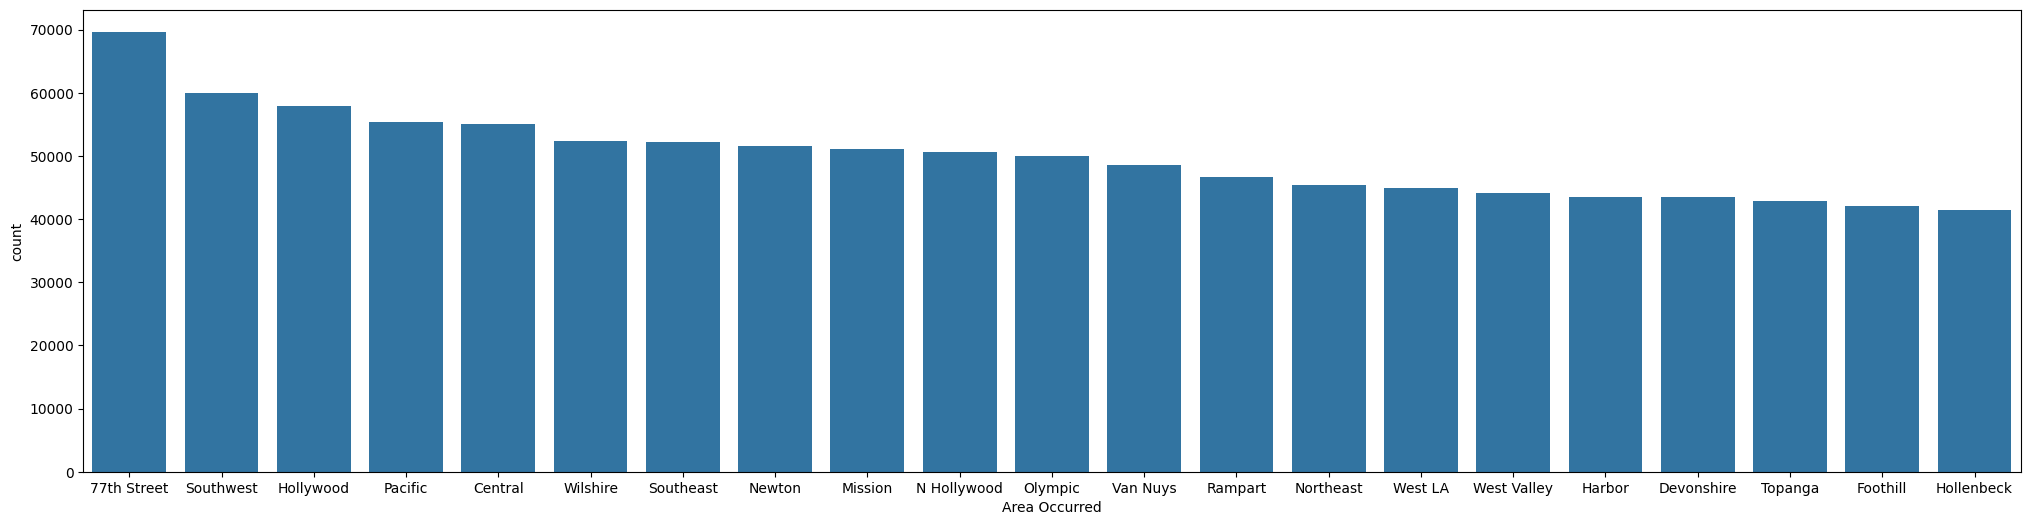

In [13]:
counts = pd.read_csv('LAPD_Calls_for_Service_2017.csv')['Area Occurred'].value_counts().reset_index()
plt.figure(figsize=(25, 6))

##Graph for overall calls in 2017

sns.barplot(data = counts, x = 'Area Occurred', y = 'count')


<Axes: xlabel='Area Name', ylabel='count'>

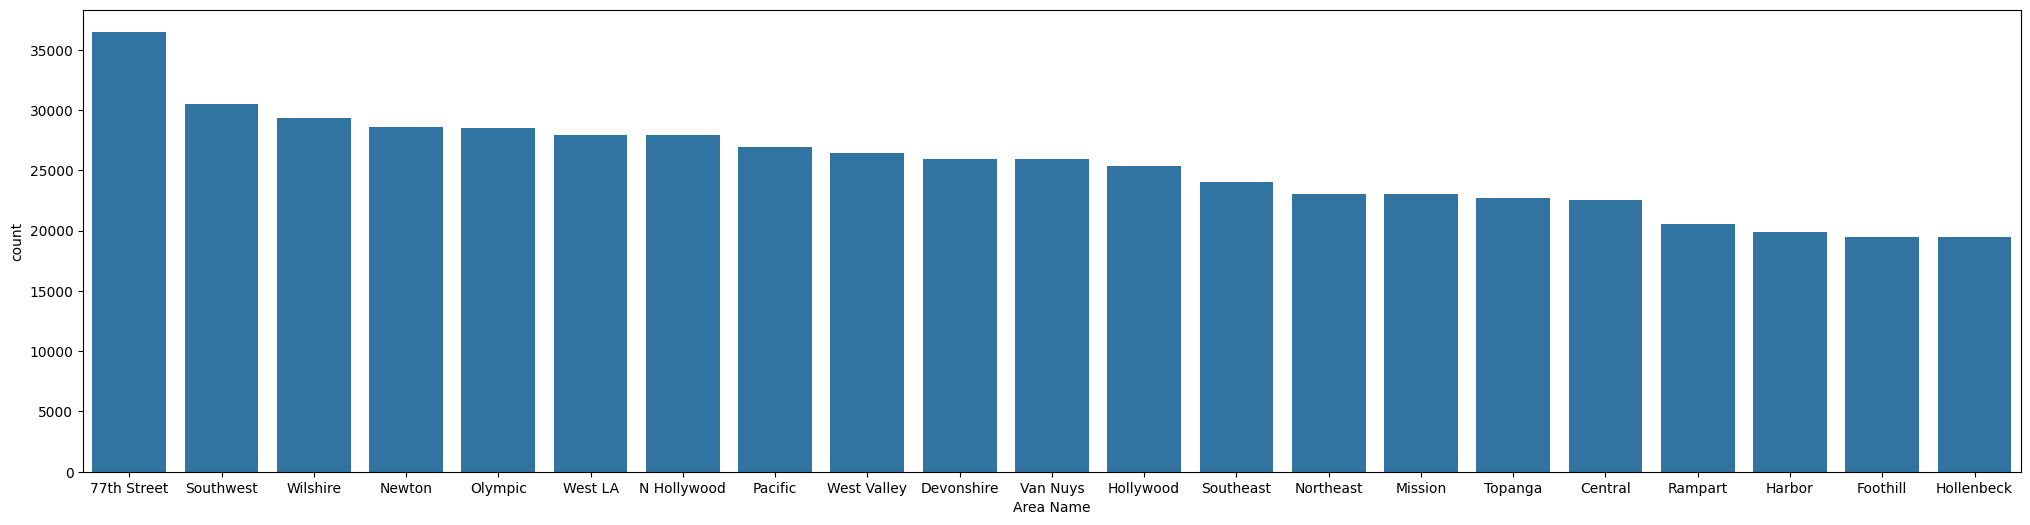

In [14]:
counts = q1data['Area Name'].value_counts().reset_index()
plt.figure(figsize=(25, 6))
sns.barplot(data = counts, x = 'Area Name',y='count')

#wilshire, Newton, West La, West Valley, Devonshire and olympic higher than they should be
#Hollywood, central significantly under
#southeast, mission lower

C:\Users\seanc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


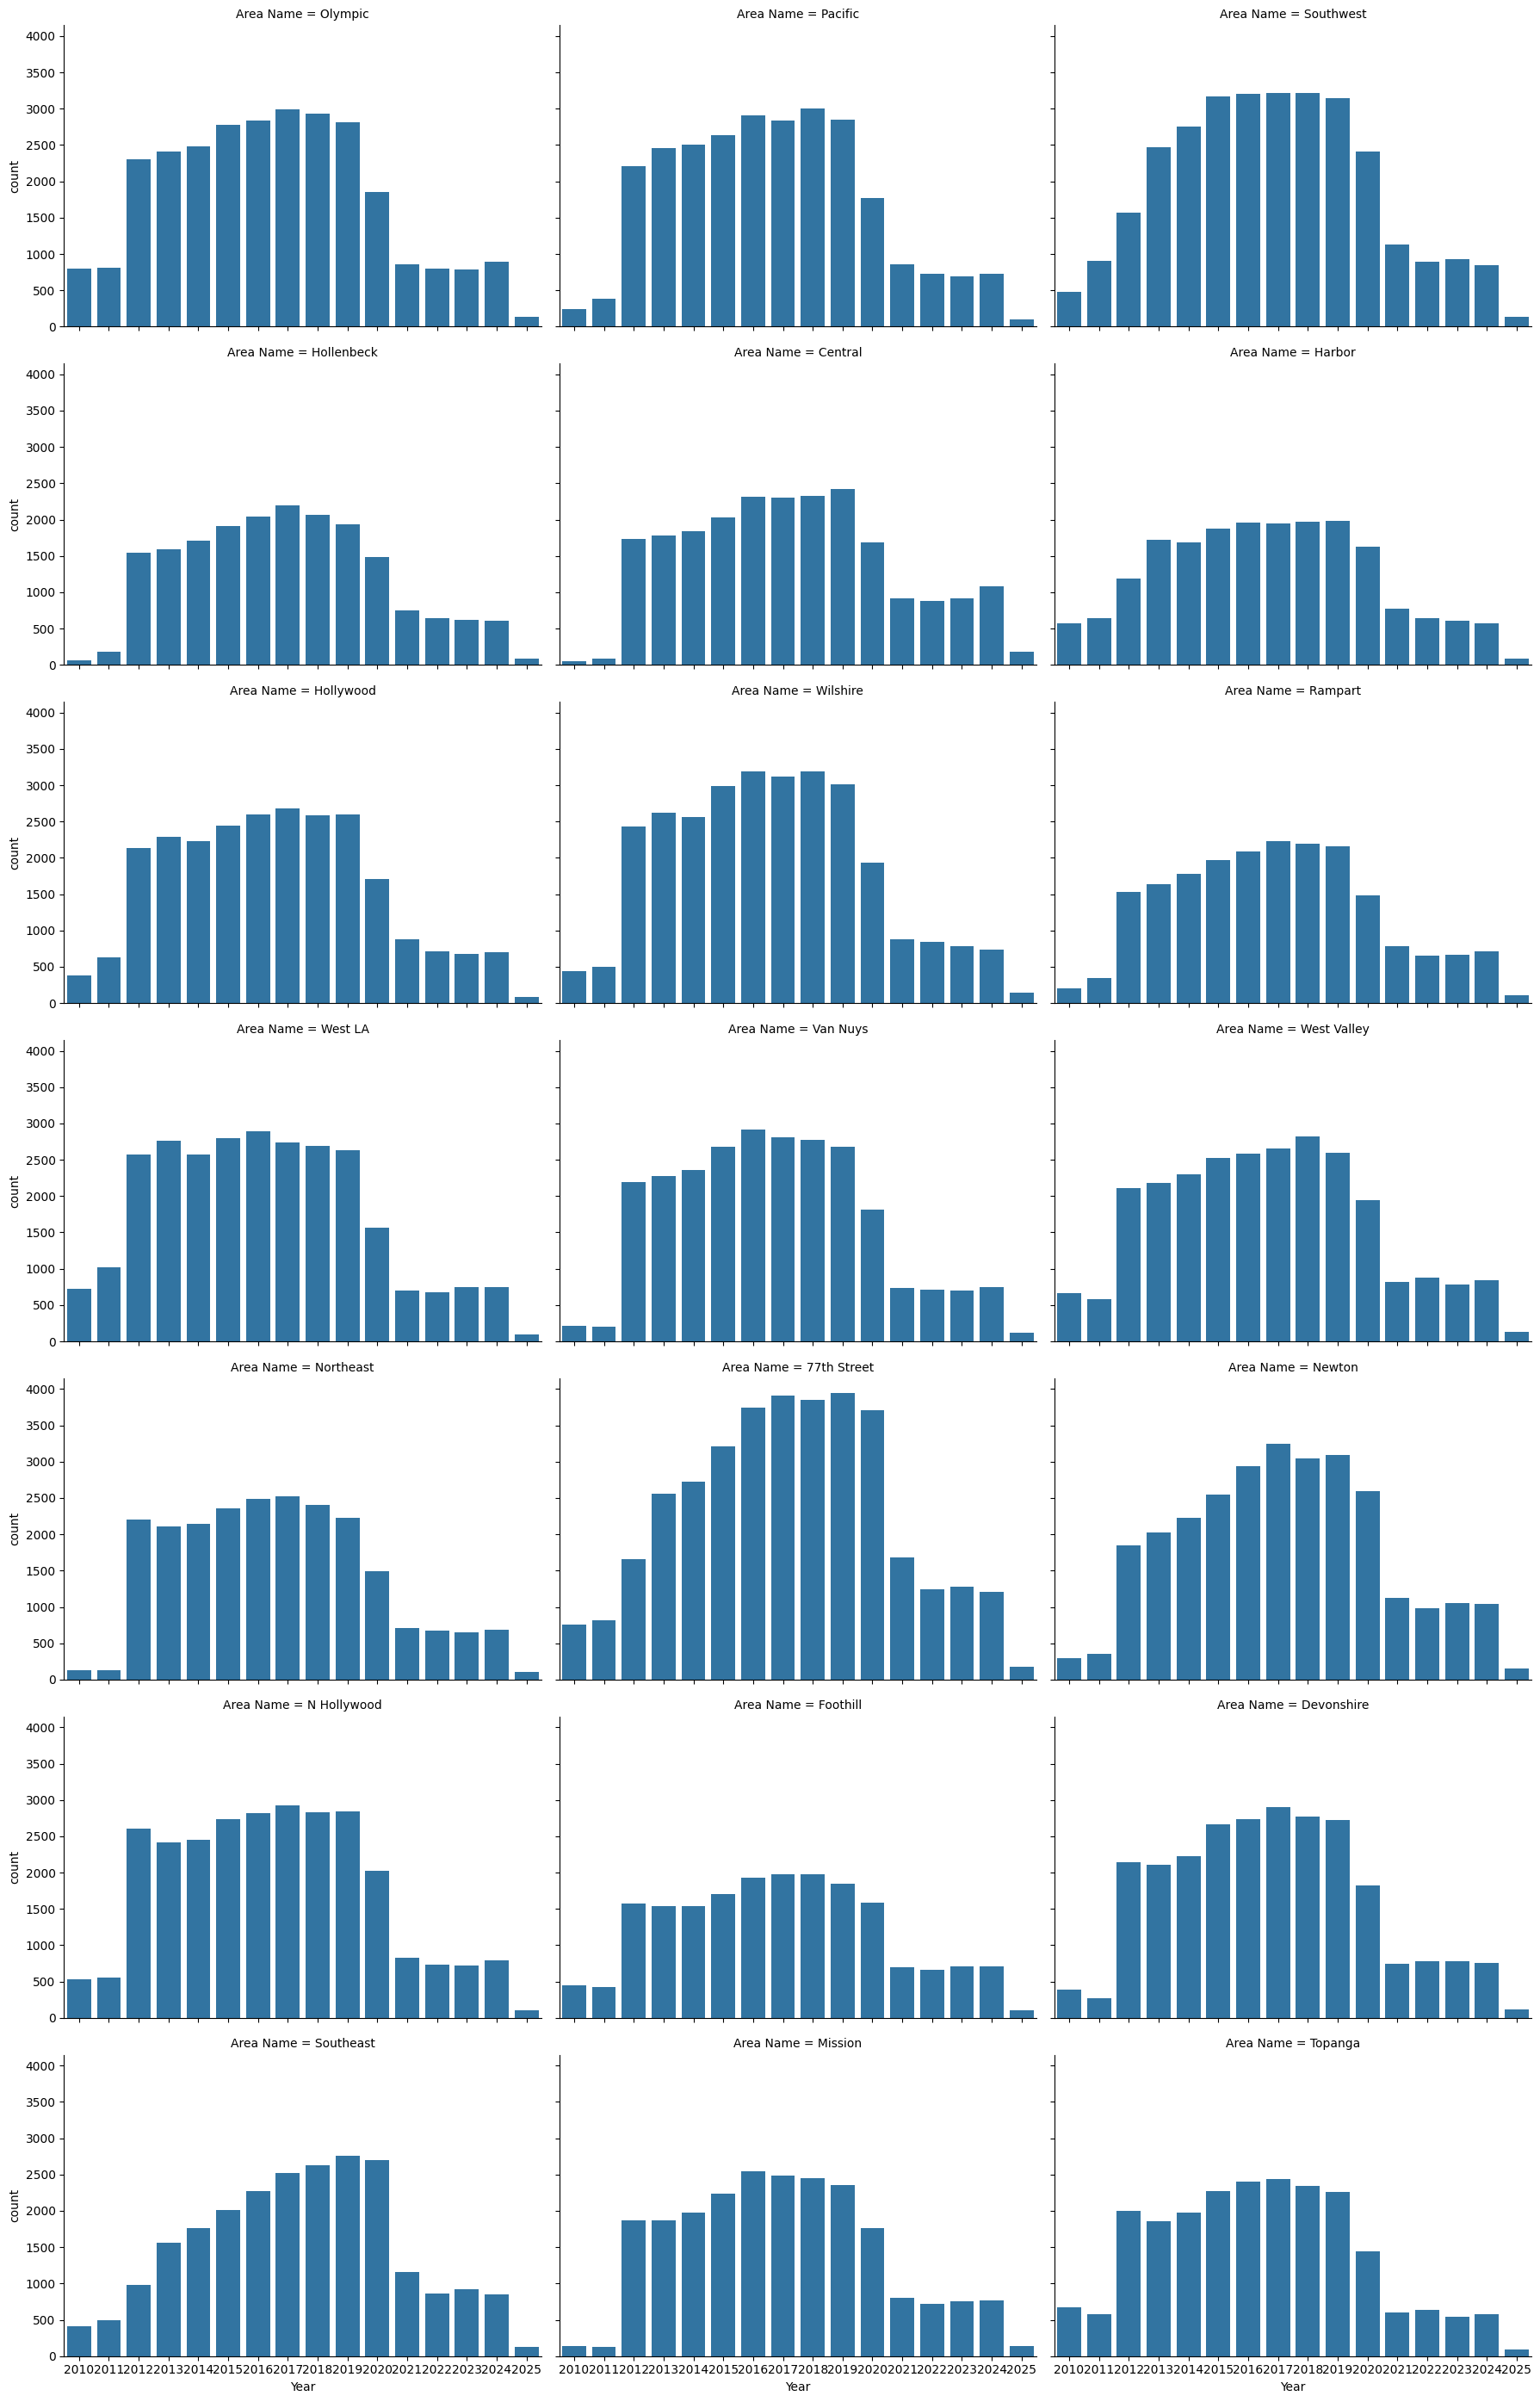

In [15]:
## Create facetgrid by year
timeByArea = sns.FacetGrid(data=q3data, col='Area Name', col_wrap=3, height = 4, aspect=1.5)
timeByArea.map(sns.countplot, 'Year')

# Notably Southeast, Rampart and 77th have consistent pre-covid

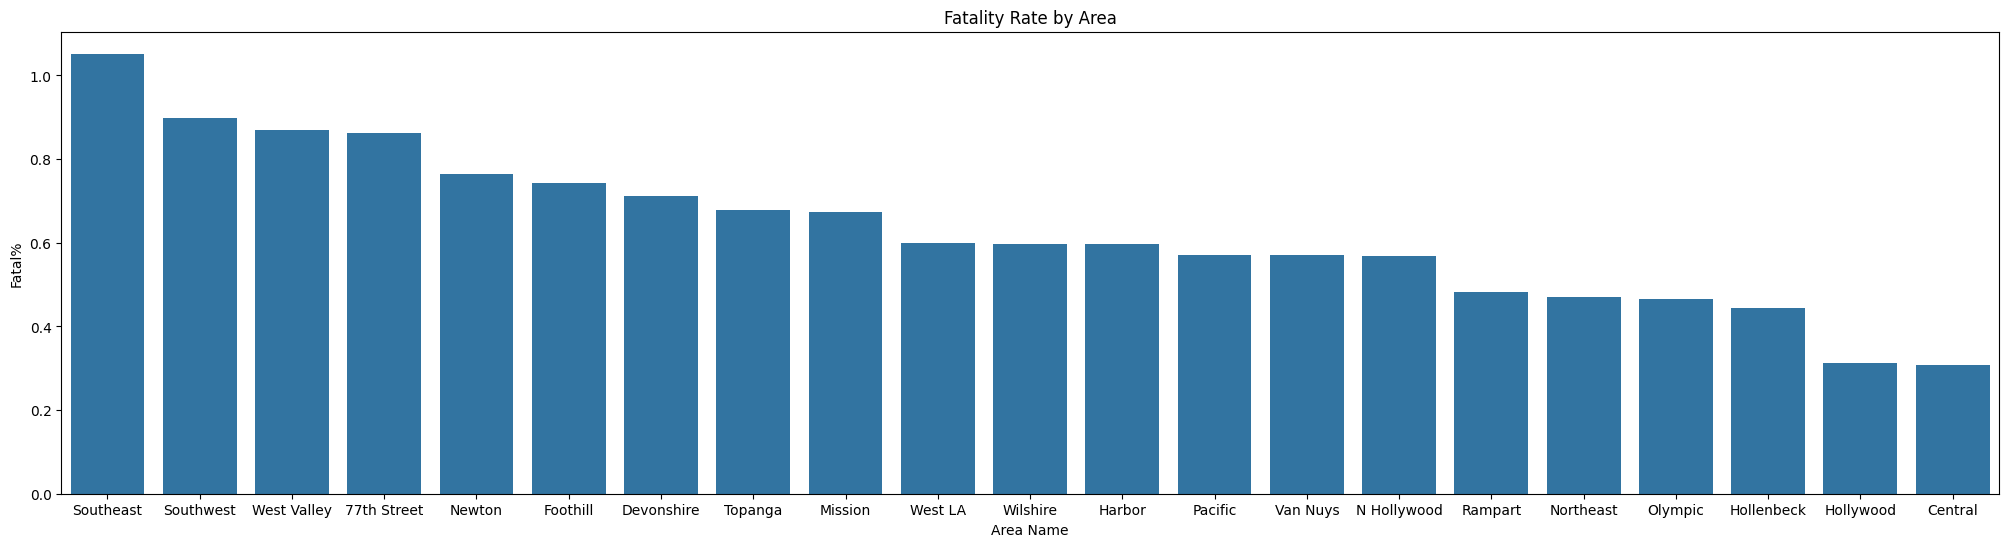

In [17]:
fatalPercents= q1data.groupby(['Area Name'])['Fatal'].sum().reset_index().sort_values(by='Area Name')
fatalPercents['Fatal%'] = 100 * fatalPercents['Fatal'] / q1data['Area Name'].value_counts().reset_index().sort_values(by='Area Name')['count']
order = fatalPercents.sort_values(by='Fatal%',ascending=False)['Area Name']
order
plt.figure(figsize=(25, 6))
sns.barplot(data=fatalPercents,x='Area Name',y='Fatal%', order=order).set_title('Fatality Rate by Area')
plt.show()

### b) Analysis 2

<Axes: xlabel='Victim Age', ylabel='Victim Sex'>

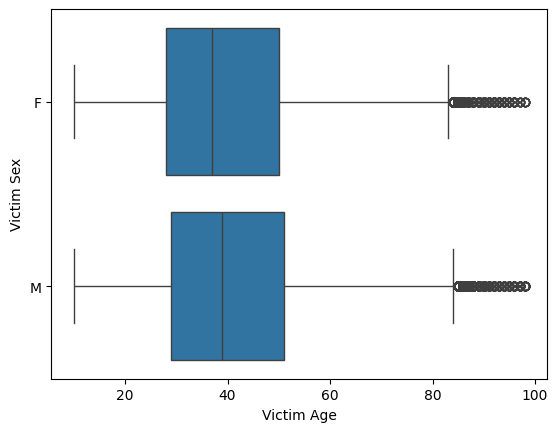

In [18]:
sns.boxplot(data=q2data,y='Victim Sex',x='Victim Age')

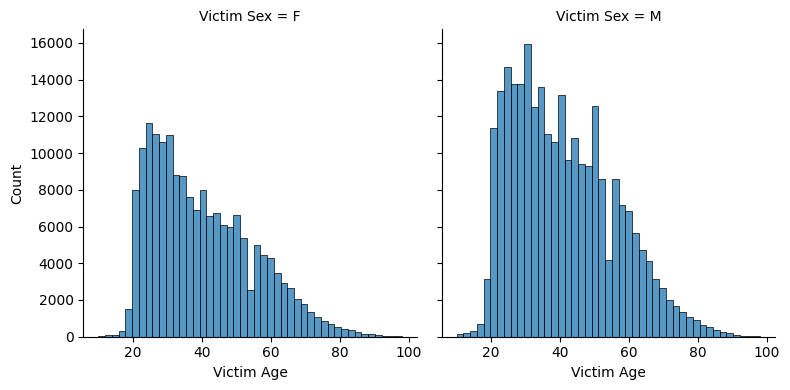

In [19]:
sexGrid = sns.FacetGrid(data=q2data, col='Victim Sex', height = 4, aspect=1.)
sexGrid.map(sns.histplot, 'Victim Age', bins = 45) 

<Axes: xlabel='Victim Sex', ylabel='Fatal'>

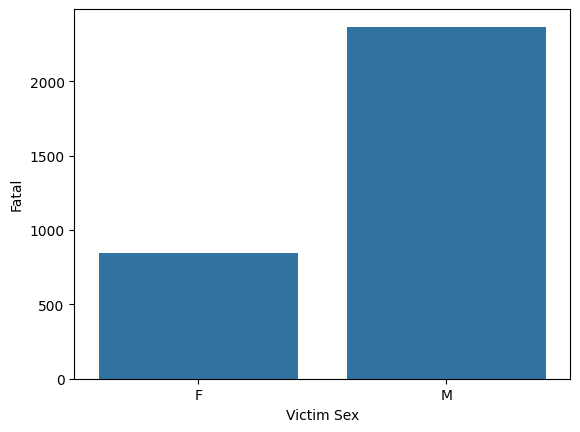

In [20]:
q2Grouped = q2dataImputed.groupby('Victim Sex')['Fatal'].sum().reset_index()
sns.barplot(q2Grouped,x='Victim Sex',y='Fatal')

<Axes: xlabel='Victim Sex', ylabel='Fatal%'>

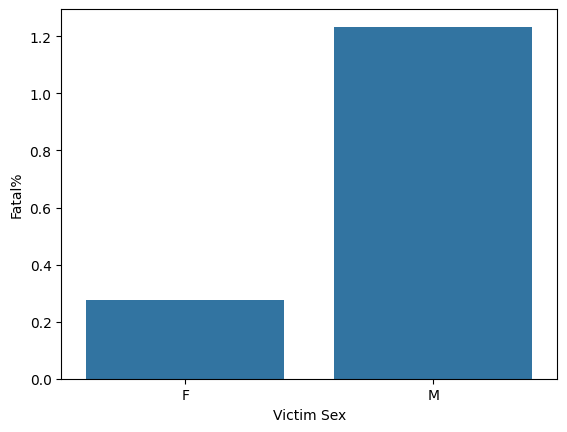

In [21]:
#| echo: false
q2Grouped['Fatal%'] = 100 * q2Grouped['Fatal']/q2dataImputed['Victim Sex'].value_counts().reset_index().sort_values(by='Victim Sex')['count']
sns.barplot(q2Grouped,x='Victim Sex', y='Fatal%')

<Axes: xlabel='Victim Age', ylabel='Fatal%'>

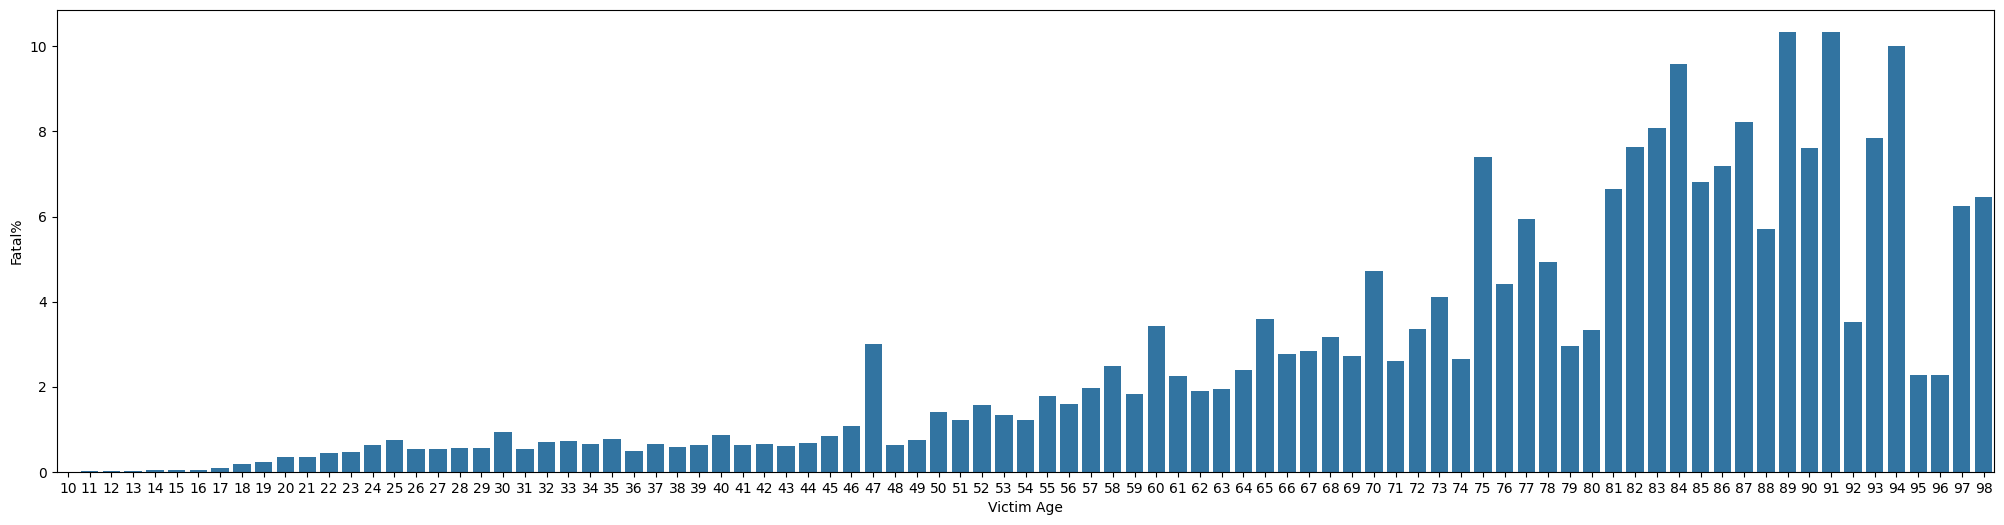

In [22]:
q2AgeGrouped = q2dataImputed.groupby('Victim Age')['Fatal'].sum().reset_index()
q2AgeGrouped['Fatal%'] = 100 * q2AgeGrouped['Fatal']/q2dataImputed['Victim Age'].value_counts().reset_index().sort_values(by='Victim Age')['count']
plt.figure(figsize=(25, 6))
q2AgeGrouped['Victim Age']=q2AgeGrouped['Victim Age'].apply(lambda x: int(x))
# We do this to clean up our x axis sinceage values are already only whole numbers
sns.barplot(q2AgeGrouped,x='Victim Age',y='Fatal%')

### c) Analysis 3

<Axes: xlabel='Month', ylabel='count'>

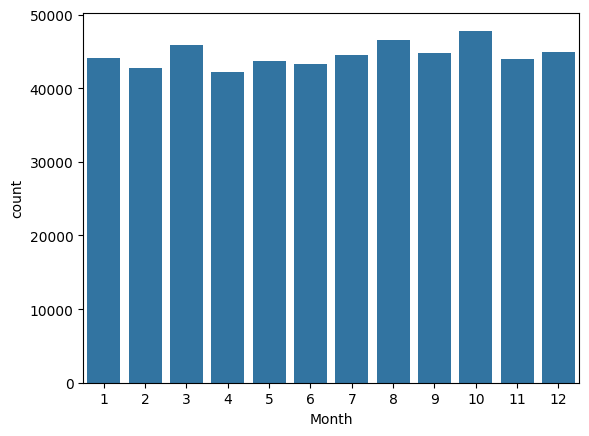

In [23]:
sns.countplot(data=q3data,x='Month')
# Simple histogram of calls by month
#There are definitely months with more calls , 

In [24]:
q3data.groupby(['Year','Month'])['Day'].value_counts().mean()
# Mean number of calls on any given day in dataset

96.34926072845293

In [25]:
dailyMean =q3data.groupby('Month')['Day'].value_counts().mean()
print("Mean Number of Incidents per Day Across Whole Dataset: "+ str(dailyMean))
# This number represents the mean of calls for each day of the year, throughout the whole timeframe. 
# That is to say, When we sum the values for all year of each month/day combination, the mean is ~1460 calls across 16 years
# This number is much more important to us than the mean above, since we are looking at trends for specific days over years
# The significance of this will be clear when we begin analysis

Mean Number of Incidents per Day Across Whole Dataset: 1459.98087431694


In [26]:
dailySD = q3data.groupby('Month')['Day'].value_counts().std()
print("Standard Deviation for Number of Incidents per Day Across Whole Dataset: "+ str(dailySD))
#standard deviation for the mean found above

Standard Deviation for Number of Incidents per Day Across Whole Dataset: 104.01610605159945


In [27]:
ordered =q3data.groupby('Month')['Day'].value_counts().reset_index().sort_values('count',ascending=False).reset_index(drop=True)
ordered.index = ordered.index + 1
ordered.head(15)
# Here we have the 15 most common days. For the most oart, these have less of a pattern
# They are, however centralized to a few peiods of time, even if it's unclear why that is the case
# Notable time periods are end of february into march,  early october, mid november (interestingly right before some of the lowest call days)
# Only obvious explanation here is the week leading up to and including Halloween. 

,Month,Day,count
1,10,31,1722
2,11,1,1697
3,2,28,1681
4,3,2,1639
5,12,13,1637
6,10,5,1636
7,10,1,1635
8,11,21,1625
9,10,2,1618
10,3,6,1605


In [28]:
ordered.tail(15).sort_values(by='count',ascending=True)
# Here we see the 15 individial days with the fewest traffic coollisiomn documented
# Unsurprisingly, we see almost all most common days are federal holidays, or in teh vicinity of federal holidays (late november, late december)
# Also unsurprisingly, the overall lowest day is February 29th, which only occurs once every 4 years

,Month,Day,count
366,2,29,434
365,12,25,1011
364,12,26,1104
363,1,2,1157
362,12,27,1163
361,12,28,1174
360,12,30,1210
359,11,28,1220
358,12,29,1224
357,5,26,1255


C:\Users\seanc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


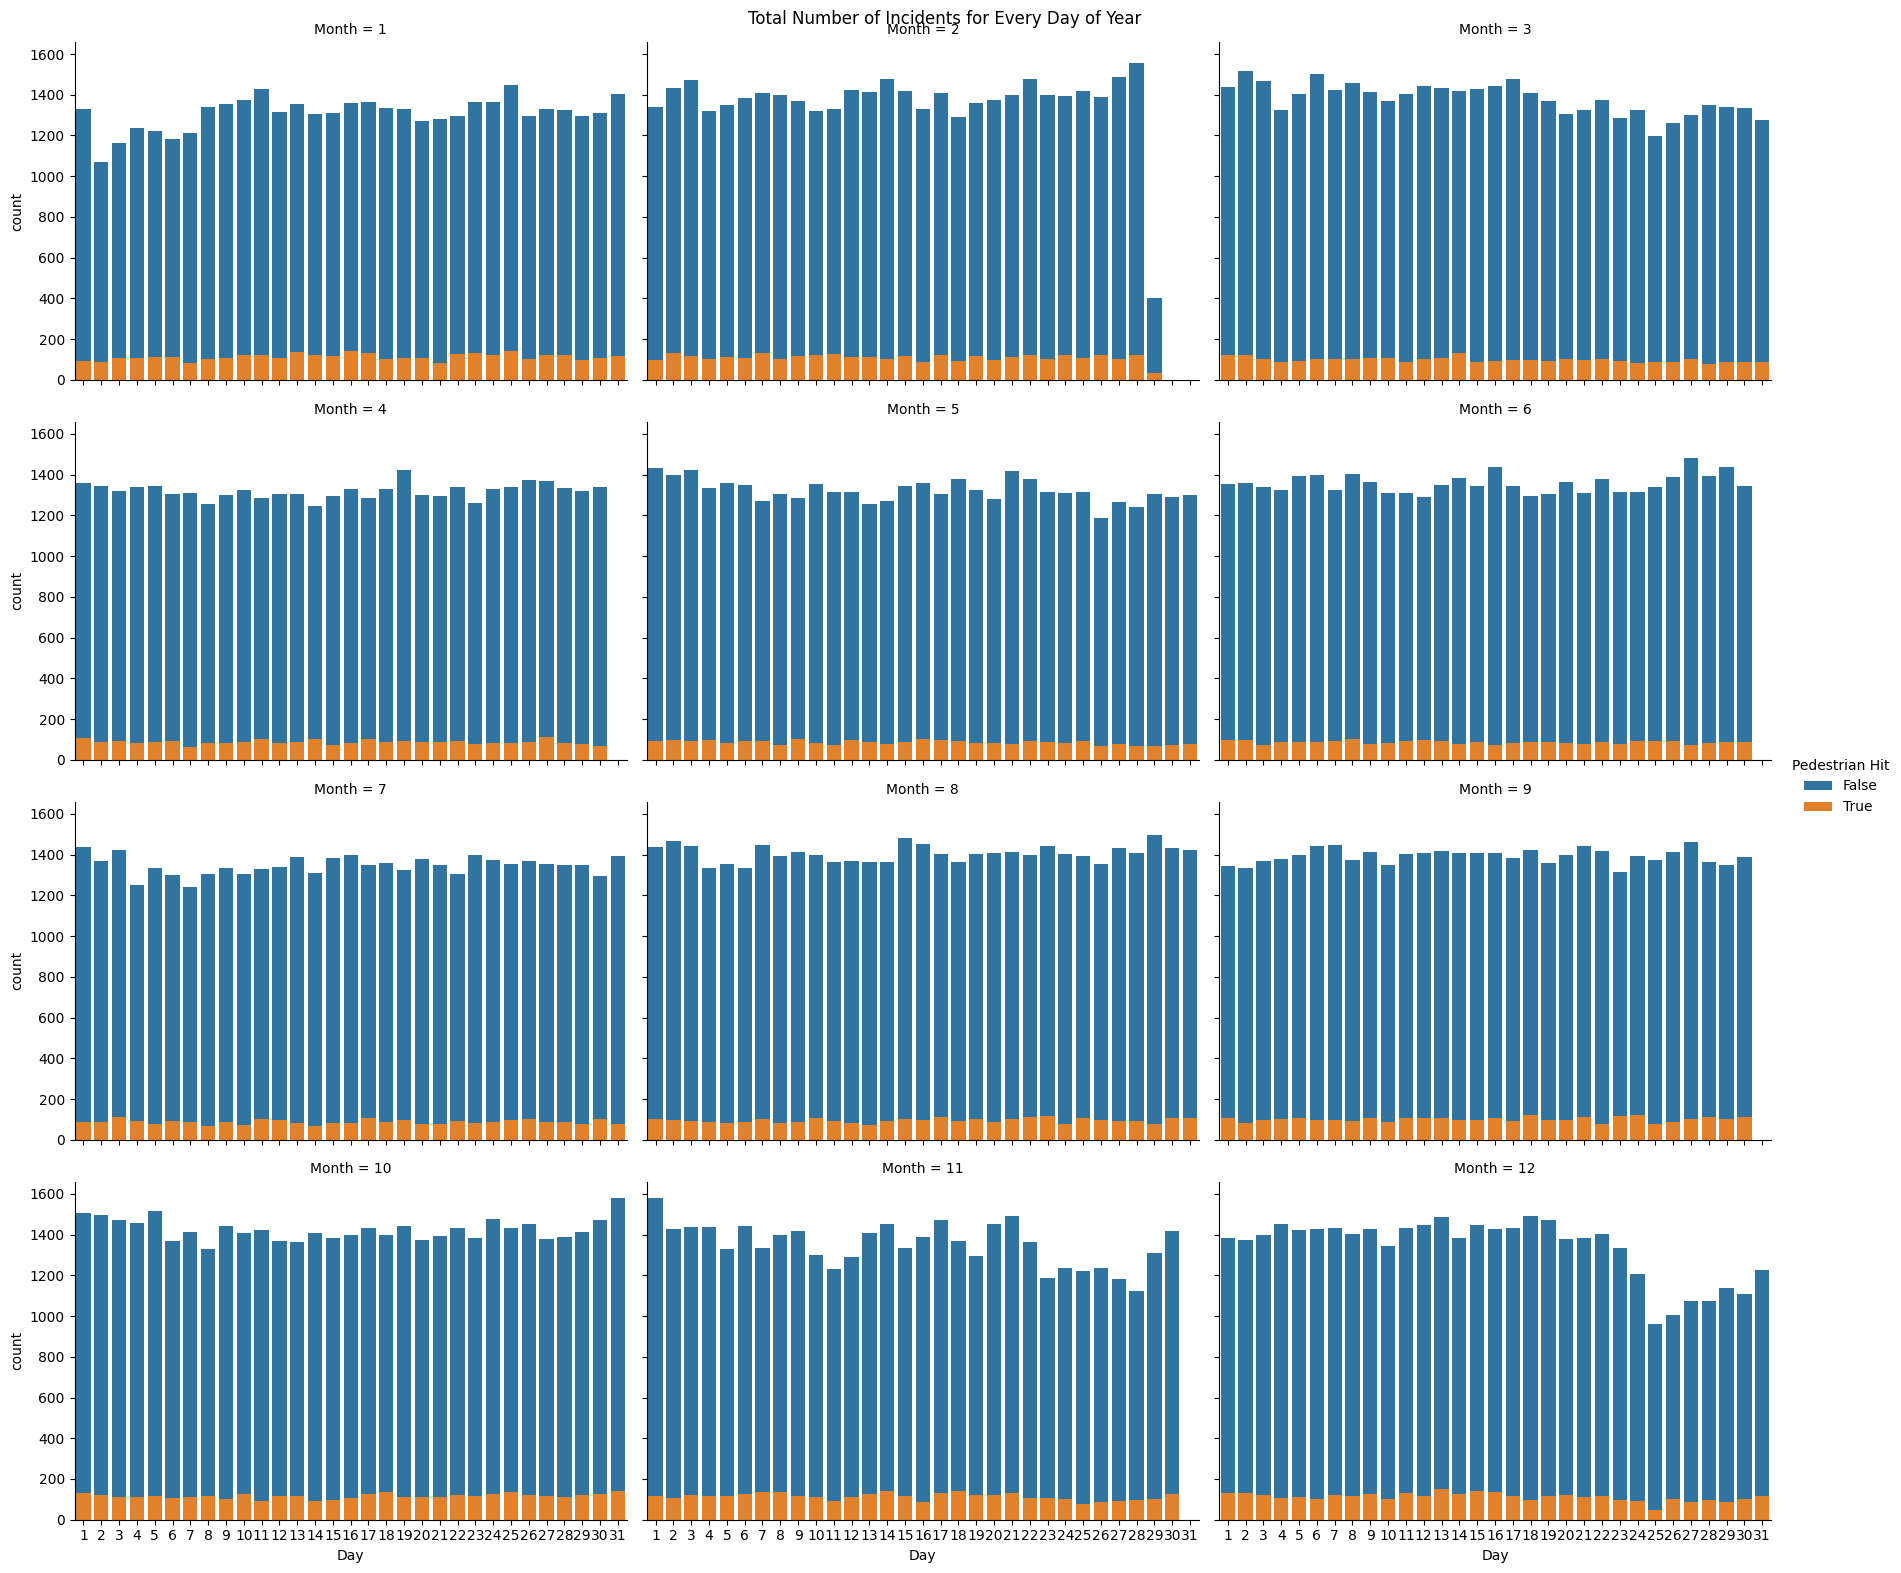

In [34]:
IncidetsByMonth = sns.FacetGrid(data=q3data, col='Month', col_wrap=3, height = 4, aspect=1.5, hue = 'Pedestrian Hit')
IncidetsByMonth.map(sns.countplot, 'Day')
IncidetsByMonth.add_legend()
IncidetsByMonth.figure.suptitle('Total Number of Incidents for Every Day of Year')
IncidetsByMonth.figure.subplots_adjust(top=0.96)
# Each instance in a day, with height representing total number of calls on that day throughout years
# Gaps come from differences in length of months
#Trends generally follow what we have seen above

In [30]:
(q3data.groupby(['Month','Day'])['Pedestrian Hit'].sum().reset_index()['Pedestrian Hit']/q3data.groupby(['Month'])['Day'].value_counts().reset_index().sort_values(['Month','Day'])['count']).sort_values(ascending=False)

365    0.116716
334    0.104918
24     0.104029
30     0.100259
347    0.099935
         ...   
225    0.048942
195    0.047718
189    0.046353
97     0.045455
359    0.036895
Length: 366, dtype: float64

Total Percentage of Incidents involving a Vehicle Hitting aPedestrian: 0.06905547456456687


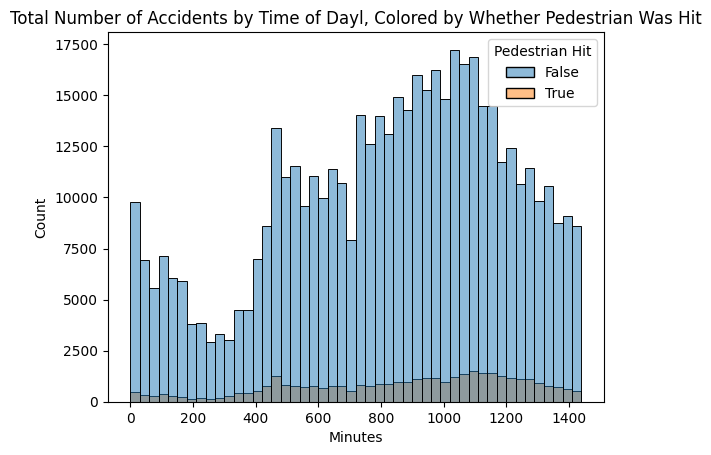

In [31]:
sns.histplot(q3data,x='Minutes',bins=48,hue='Pedestrian Hit').set_title('Total Number of Accidents by Time of Dayl, Colored by Whether Pedestrian Was Hit')
# Total data by number of calls in given 48 intervals
percentPedT = (q3data['Pedestrian Hit']==True).sum()/len(q3data)
print('Total Percentage of Incidents involving a Vehicle Hitting aPedestrian: ' +str(percentPedT))

Percentage of Incidents involving a Vehicle Hitting a Pedestrian On Halloween: 0.08304297328687572


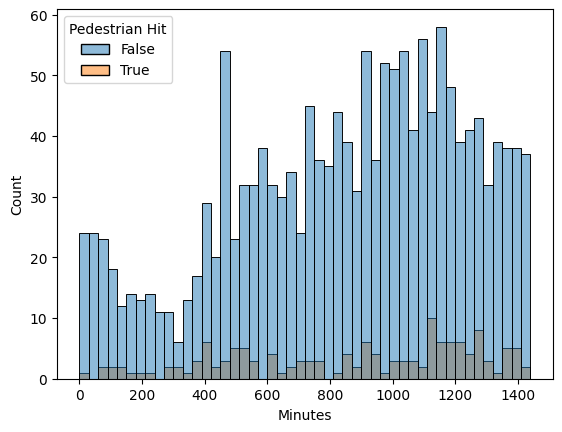

In [32]:
octoberData=q3data[q3data['Month']==10]
halloweenData =octoberData[octoberData['Day']==31]
sns.histplot(halloweenData,x='Minutes',bins=48, hue='Pedestrian Hit')
percentPedH = (halloweenData['Pedestrian Hit']==True).sum()/len(halloweenData)
print('Percentage of Incidents involving a Vehicle Hitting a Pedestrian On Halloween: ' +str(percentPedH))
# Halloween Data

Percentage of Incidents involving a Vehicle Hitting a Pedestrian On November 1st: 0.0801223241590214


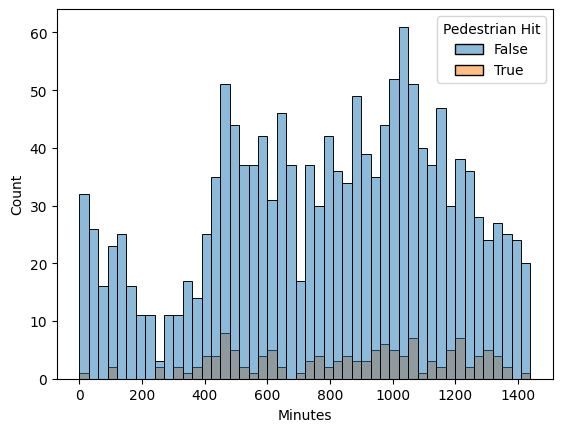

In [33]:
novData=q3data[q3data['Month']==10]
postHalloweenData =novData[novData['Day']==1]
sns.histplot(postHalloweenData,x='Minutes',bins=48,hue='Pedestrian Hit')
percentPedNO = (postHalloweenData['Pedestrian Hit']==True).sum()/len(postHalloweenData)
print('Percentage of Incidents involving a Vehicle Hitting a Pedestrian On November 1st: ' + str(percentPedNO))
# November 1st